# Markov Chains, Phonons, and the 1D Heat Equation

In this notebook you will compare a Markov-chain model of phonon transport with the 1D heat equation.

## What you need to do
Construct the Markov matrix P in the student section. The rest of the notebook evolves both models and compares them visually.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
M=101
steps=300
snapshot_times=[0,20,50,100,200,300]
p=0.2

u0=np.zeros(M)
u0[45:56]=1.0

## STUDENT SECTION
Build the Markov matrix with reflecting boundaries.

In [3]:
P=np.zeros((M,M))

# STUDENT WORK HERE


0.0


## Markov evolution

In [4]:
u_markov=u0.copy()
markov_snapshots={0:u_markov.copy()}
for n in range(1,steps+1):
    u_markov=P.T@u_markov
    if n in snapshot_times:
        markov_snapshots[n]=u_markov.copy()

## Heat equation evolution

In [5]:
u_heat=u0.copy()
heat_snapshots={0:u_heat.copy()}
for n in range(1,steps+1):
    unew=u_heat.copy()
    unew[1:-1]=(1-p)*u_heat[1:-1]+0.5*p*(u_heat[:-2]+u_heat[2:])
    unew[0]=(1-p)*u_heat[0]+p*u_heat[1]
    unew[-1]=(1-p)*u_heat[-1]+p*u_heat[-2]
    u_heat=unew
    if n in snapshot_times:
        heat_snapshots[n]=u_heat.copy()

## Comparison

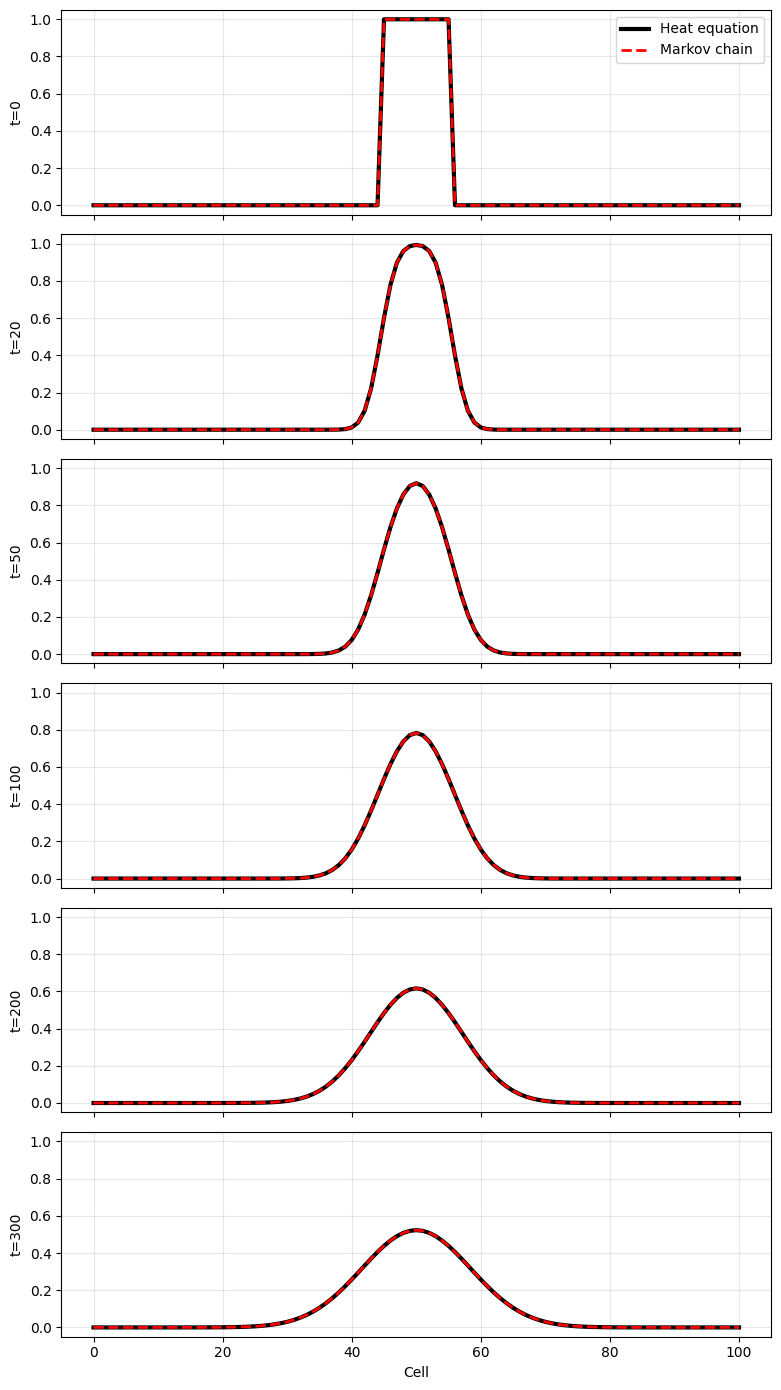

In [11]:
fig, axes = plt.subplots(len(snapshot_times), 1, figsize=(8, 14), sharex=True, sharey=True)
x = np.arange(M)
for ax, t in zip(axes, snapshot_times):
    ax.plot(x, heat_snapshots[t], "k", lw=3, label="Heat equation")
    ax.plot(x, markov_snapshots[t], "r--", lw=2, label="Markov chain")
    ax.set_ylabel(f"t={t}")
    ax.grid(alpha=0.3)
    if t == 0:
        ax.legend()
axes[-1].set_xlabel("Cell")
plt.tight_layout()
plt.show()

## Reflection Questions
1. Why do the two models agree?
2. Which assumptions are encoded in P?
3. What changes if hotter cells emit phonons more frequently?